In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.bbox'] = 'tight'

df_app = pd.read_csv('../data/processed/fact_applications.csv')
df_bureau = pd.read_csv('../data/processed/dim_bureau_history.csv')
df_prev = pd.read_csv('../data/processed/dim_prev_applications.csv')

df_eda = (
    df_app
    .merge(df_bureau, on='sk_id_curr', how='left')
    .merge(df_prev, on='sk_id_curr', how='left')
)

history_cols = ['bureau_total_loans', 'bureau_active_loans', 'bureau_has_overdue', 
                'prev_app_count', 'prev_refused_count']
df_eda[history_cols] = df_eda[history_cols].fillna(0)

print(f"Dataset EDA terintegrasi siap: {df_eda.shape[0]:,} baris x {df_eda.shape[1]} kolom")

Dataset EDA terintegrasi siap: 307,504 baris x 45 kolom


Cell 2

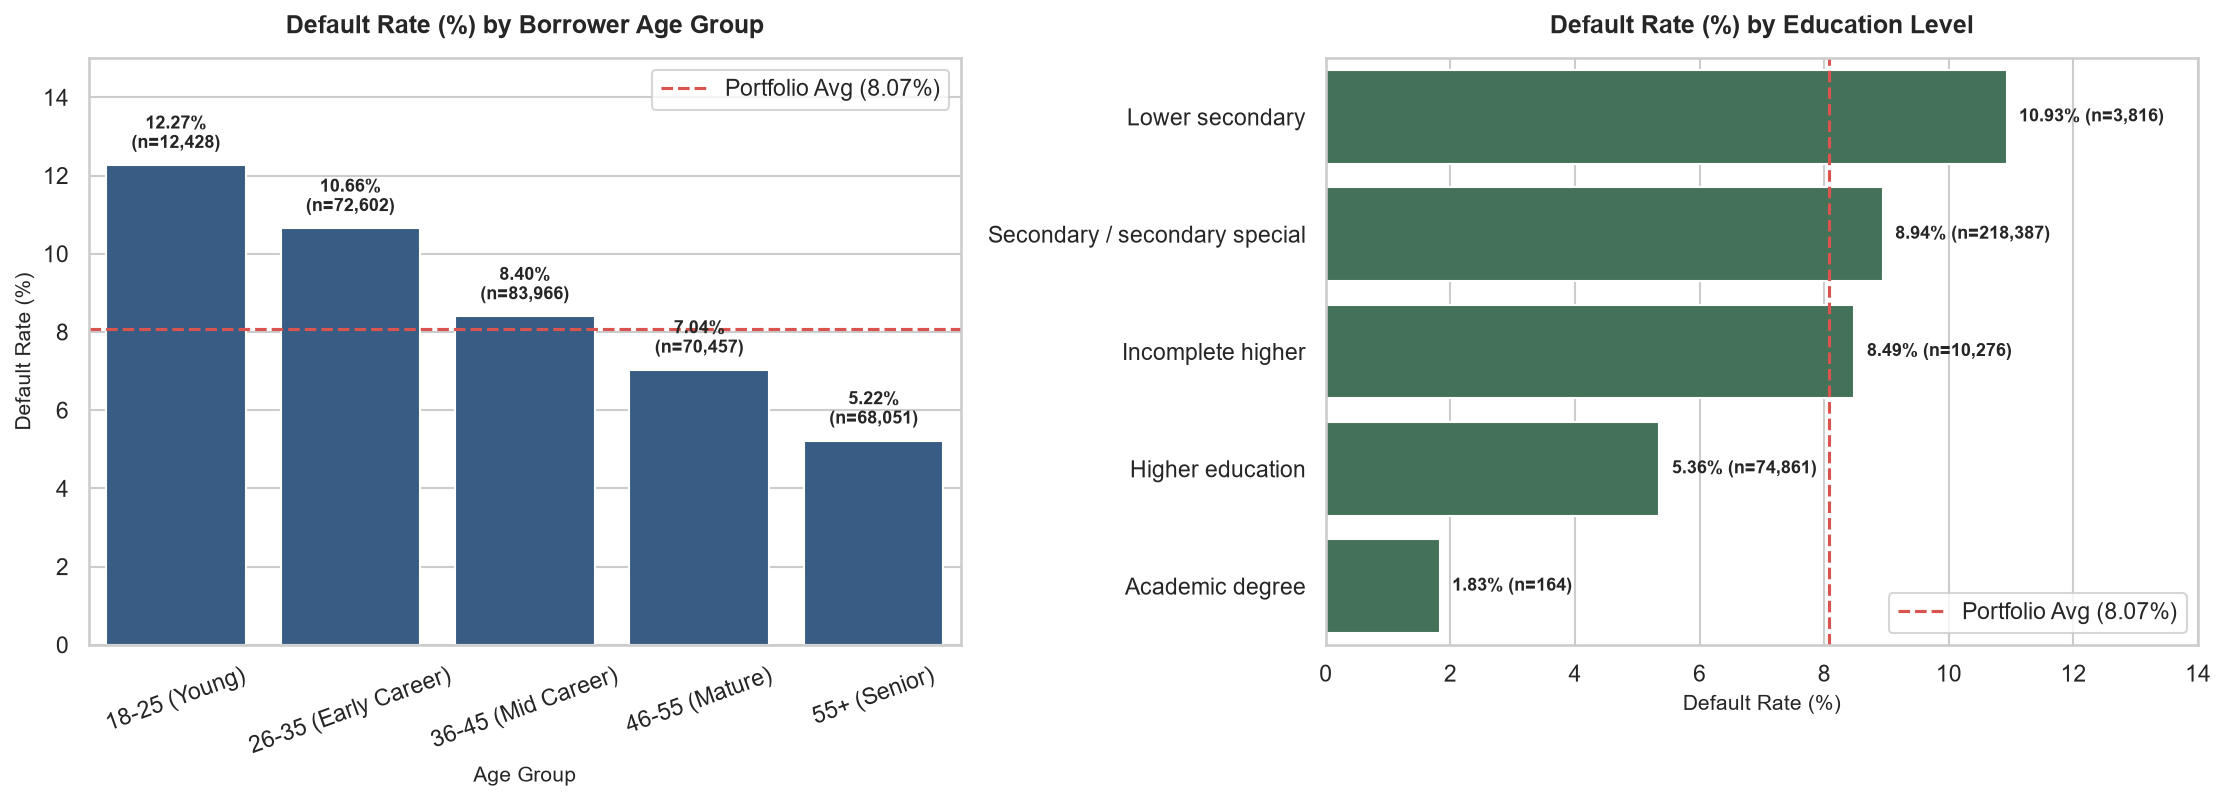

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
baseline_default = df_eda['target'].mean() * 100

age_order = ['18-25 (Young)', '26-35 (Early Career)', '36-45 (Mid Career)', '46-55 (Mature)', '55+ (Senior)']
age_summary = (
    df_eda.groupby('age_group', observed=False)['target']
    .agg(total='count', default_rate=lambda x: x.mean() * 100)
    .reindex(age_order)
    .reset_index()
)

sns.barplot(data=age_summary, x='age_group', y='default_rate', ax=axes[0], color='#2b5c8f')
axes[0].axhline(baseline_default, color='#d9534f', linestyle='--', linewidth=1.5, label=f'Portfolio Avg ({baseline_default:.2f}%)')
axes[0].set_title('Default Rate (%) by Borrower Age Group', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Age Group', fontsize=10)
axes[0].set_ylabel('Default Rate (%)', fontsize=10)
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_ylim(0, 15)
axes[0].legend()

for i, row in age_summary.iterrows():
    axes[0].text(i, row['default_rate'] + 0.3, f"{row['default_rate']:.2f}%\n(n={row['total']:,})", 
                 ha='center', va='bottom', fontsize=8.5, fontweight='bold')

edu_summary = (
    df_eda.groupby('name_education_type')['target']
    .agg(total='count', default_rate=lambda x: x.mean() * 100)
    .sort_values('default_rate', ascending=False)
    .reset_index()
)

sns.barplot(data=edu_summary, y='name_education_type', x='default_rate', ax=axes[1], color='#3b7a57')
axes[1].axvline(baseline_default, color='#d9534f', linestyle='--', linewidth=1.5, label=f'Portfolio Avg ({baseline_default:.2f}%)')
axes[1].set_title('Default Rate (%) by Education Level', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Default Rate (%)', fontsize=10)
axes[1].set_ylabel('')
axes[1].set_xlim(0, 14)
axes[1].legend()

for i, row in edu_summary.iterrows():
    axes[1].text(row['default_rate'] + 0.2, i, f"{row['default_rate']:.2f}% (n={row['total']:,})", 
                 va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/01_default_by_demographics.png')
plt.show()

CELL 3

D:\Temp\ipykernel_16468\2257249714.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
D:\Temp\ipykernel_16468\2257249714.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


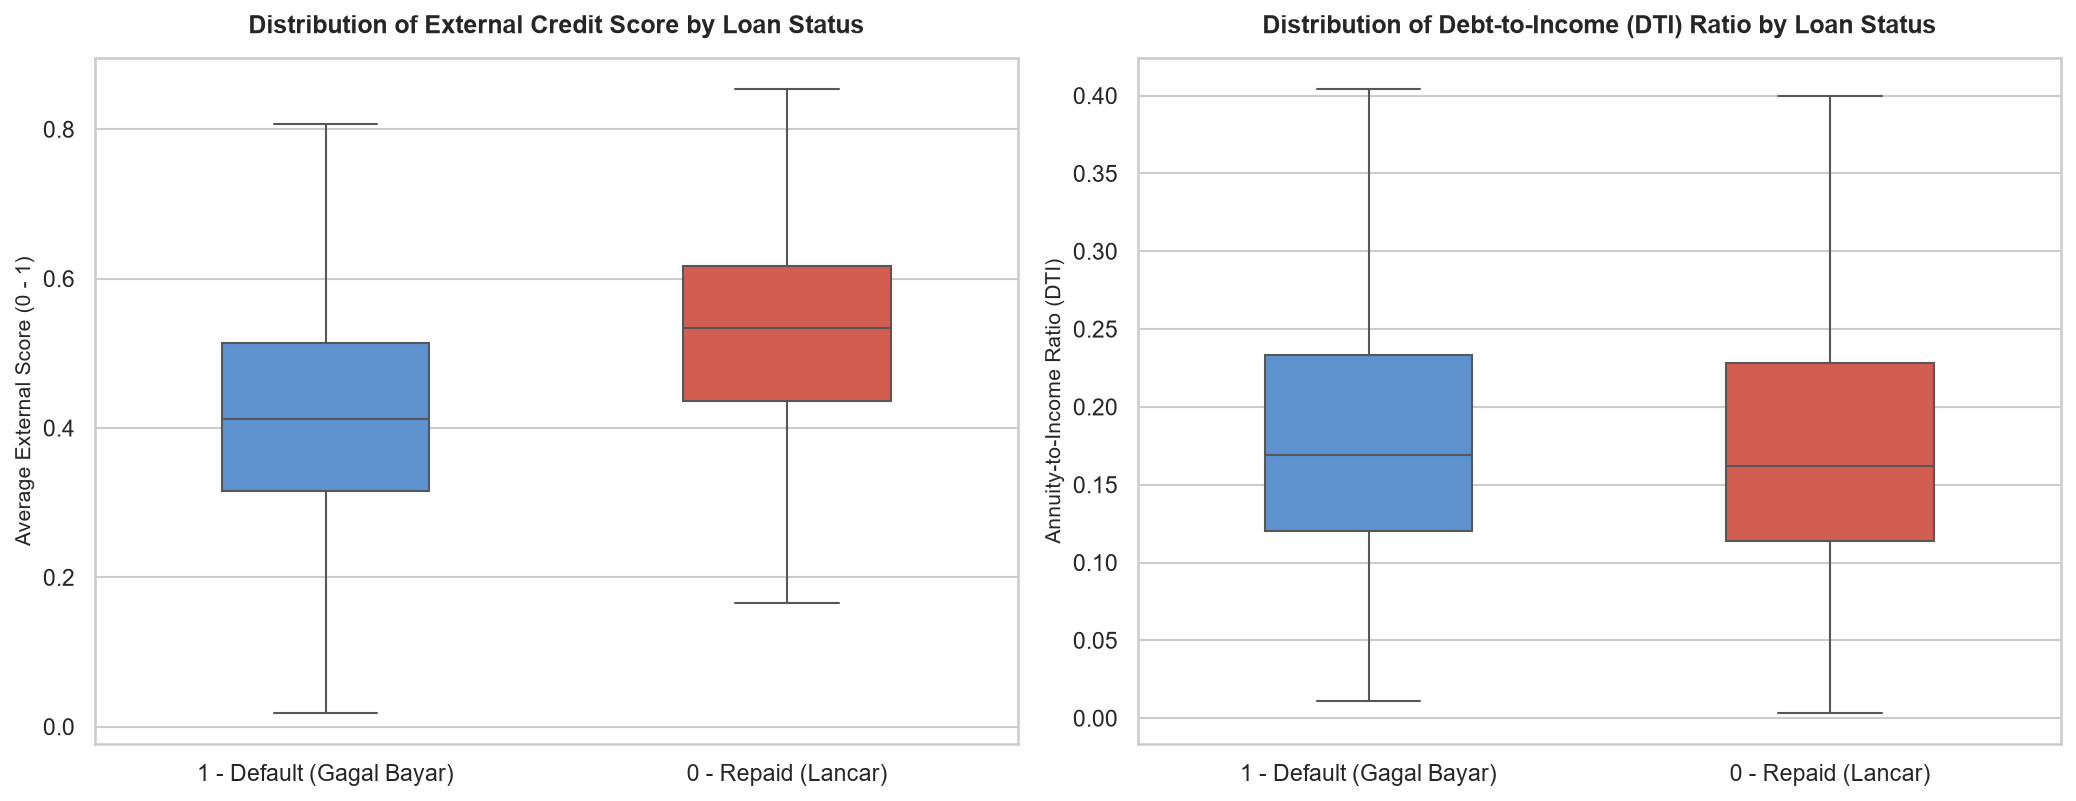

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

df_plot = df_eda.copy()
df_plot['Loan Status'] = df_plot['target'].map({0: '0 - Repaid (Lancar)', 1: '1 - Default (Gagal Bayar)'})

sns.boxplot(
    data=df_plot, x='Loan Status', y='avg_ext_source', 
    ax=axes[0], palette=['#4a90e2', '#e74c3c'], width=0.45, showfliers=False
)
axes[0].set_title('Distribution of External Credit Score by Loan Status', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('')
axes[0].set_ylabel('Average External Score (0 - 1)', fontsize=10)

sns.boxplot(
    data=df_plot, x='Loan Status', y='annuity_to_income_ratio', 
    ax=axes[1], palette=['#4a90e2', '#e74c3c'], width=0.45, showfliers=False
)
axes[1].set_title('Distribution of Debt-to-Income (DTI) Ratio by Loan Status', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('')
axes[1].set_ylabel('Annuity-to-Income Ratio (DTI)', fontsize=10)

plt.tight_layout()
plt.savefig('../figures/02_financial_ratios_distribution.png')
plt.show()

CELL 4

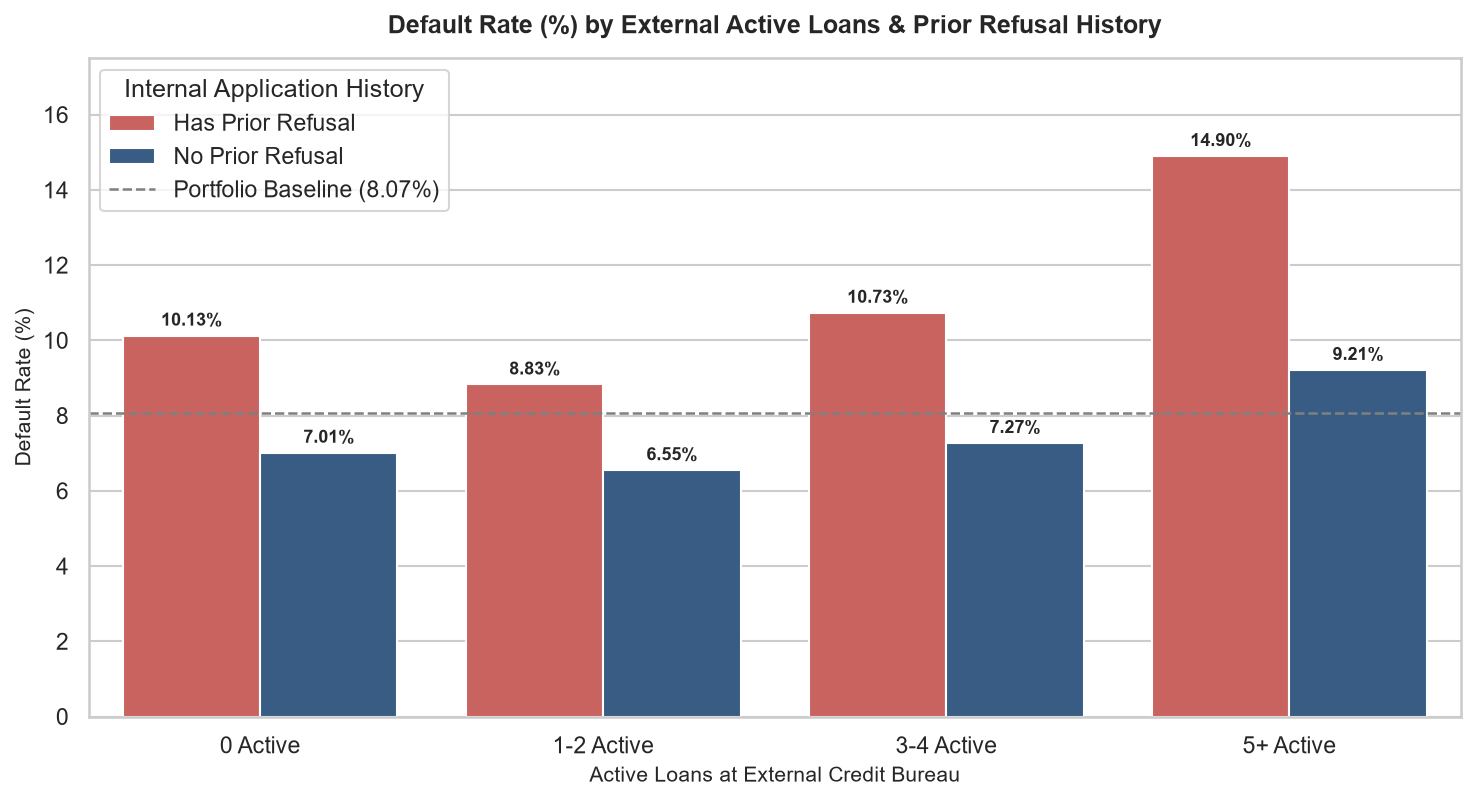

In [5]:
df_eda['external_loans_group'] = pd.cut(
    df_eda['bureau_active_loans'],
    bins=[-1, 0, 2, 4, 100],
    labels=['0 Active', '1-2 Active', '3-4 Active', '5+ Active']
)
df_eda['prior_refusal_status'] = np.where(
    df_eda['prev_refused_count'] > 0, 'Has Prior Refusal', 'No Prior Refusal'
)

history_summary = (
    df_eda.groupby(['external_loans_group', 'prior_refusal_status'], observed=False)['target']
    .agg(count='count', default_rate=lambda x: x.mean() * 100)
    .reset_index()
)

plt.figure(figsize=(10, 5.5))
ax = sns.barplot(
    data=history_summary, x='external_loans_group', y='default_rate', 
    hue='prior_refusal_status', palette=['#d9534f', '#2b5c8f']
)

plt.axhline(df_eda['target'].mean() * 100, color='gray', linestyle='--', linewidth=1.2, label='Portfolio Baseline (8.07%)')
plt.title('Default Rate (%) by External Active Loans & Prior Refusal History', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Active Loans at External Credit Bureau', fontsize=10)
plt.ylabel('Default Rate (%)', fontsize=10)
plt.ylim(0, 17.5)
plt.legend(title='Internal Application History')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/03_credit_history_impact.png')
plt.show()

CELL 5

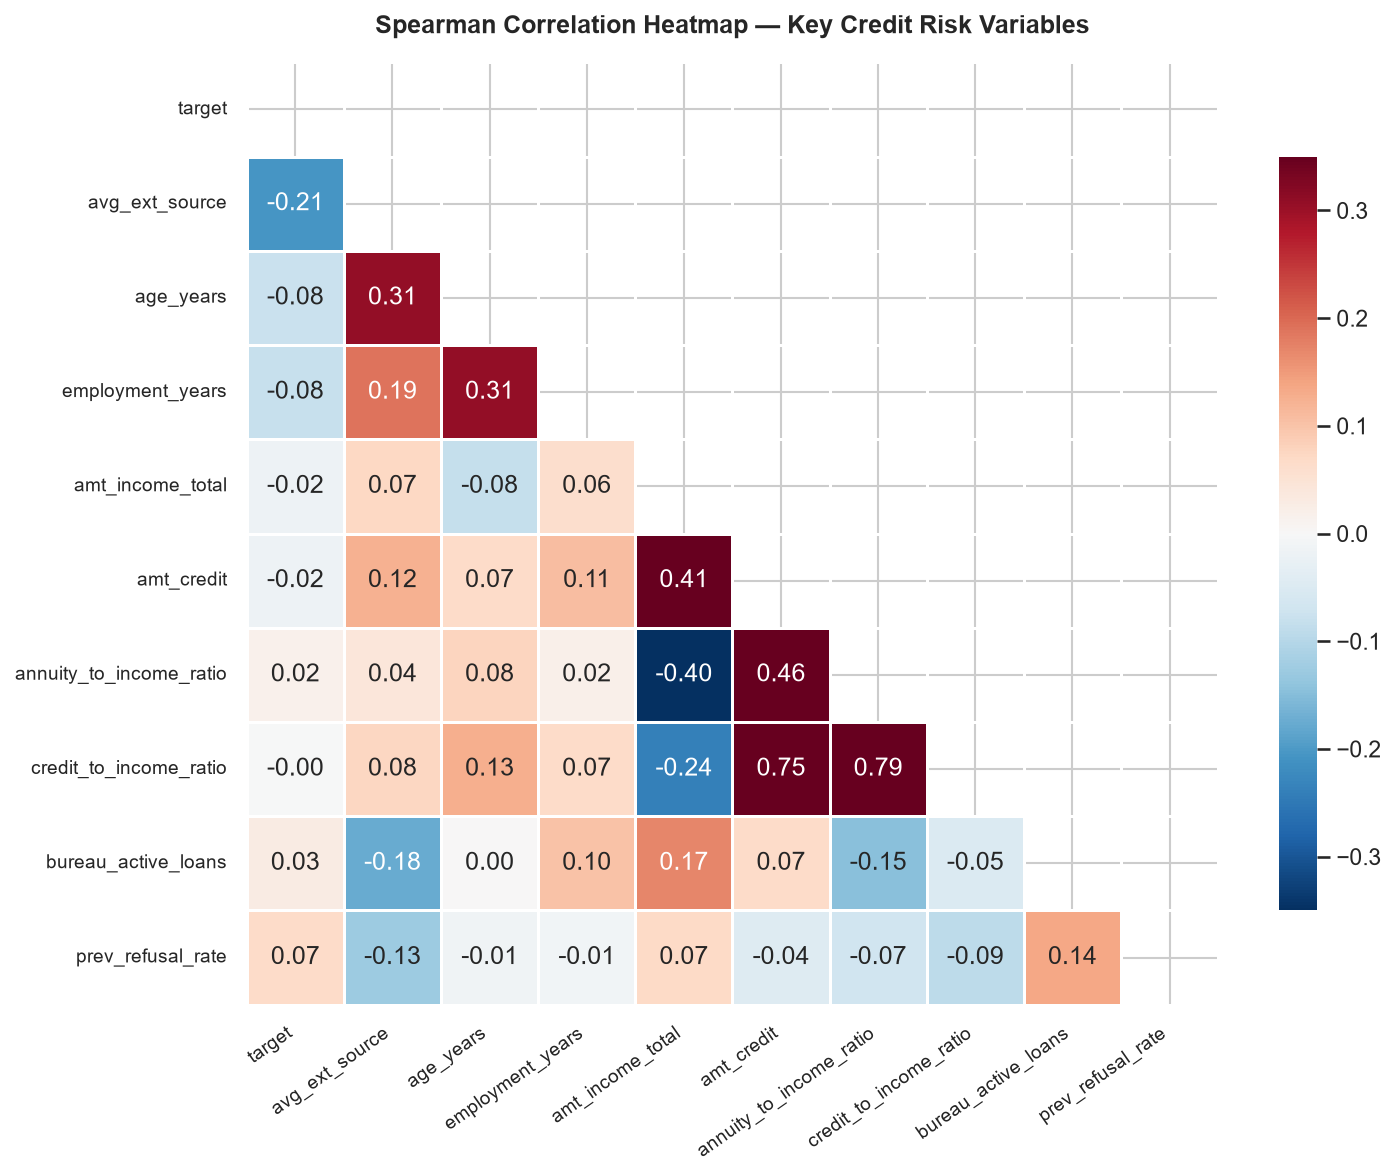

In [6]:
corr_cols = [
    'target', 'avg_ext_source', 'age_years', 'employment_years',
    'amt_income_total', 'amt_credit', 'annuity_to_income_ratio',
    'credit_to_income_ratio', 'bureau_active_loans', 'prev_refusal_rate'
]

corr_matrix = df_eda[corr_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', 
    center=0, vmin=-0.35, vmax=0.35, linewidths=0.5, cbar_kws={'shrink': 0.8}
)
plt.title('Spearman Correlation Heatmap — Key Credit Risk Variables', fontsize=12, fontweight='bold', pad=14)
plt.xticks(rotation=35, ha='right', fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.savefig('../figures/04_spearman_correlation.png')
plt.show()